# SAR to Optical -- Seg-CycleGAN (SegFormer + SegEarth-OV) -- H100 run

## Step 0 -- Get dataset from Kaggle onto disk (Jarvis / H100 runtime)


In [1]:
import sys
print(sys.executable)

/home/venvs/segearth/bin/python


In [2]:
# ---- Jarvis runtime workspace root ----
# No Google Drive here -- /home is the persistent path on this Jarvis instance
# (survives pause/destroy; /root and other paths do not), so everything
# (dataset, SegEarth-OV repo, masks, checkpoints) lives under one local root.
# Change this ONE line if your Jarvis instance's persistent path differs.
from pathlib import Path
PROJECT_ROOT = Path("/home/seg_cyclegan_project")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

# ---- Kaggle credentials (kagglehub reads the same kaggle.json / env vars as the CLI) ----
# Option A (recommended): upload your kaggle.json (from kaggle.com -> Settings -> API ->
#   "Create New Token") into ~/.kaggle/kaggle.json on this runtime before running this cell.
# Option B: set the two env vars below directly instead of using a kaggle.json file.
import os

KAGGLE_CONFIG_DIR = Path.home() / ".kaggle"
KAGGLE_CONFIG_DIR.mkdir(parents=True, exist_ok=True)

# If using Option B, uncomment and fill these in (and skip uploading kaggle.json):
# os.environ["KAGGLE_USERNAME"] = "your_kaggle_username"
os.environ["KAGGLE_KEY"] = "KGAT_987850e88b99747485e4fc0d2db7d352"

# if (KAGGLE_CONFIG_DIR / "kaggle.json").exists():
#     os.chmod(KAGGLE_CONFIG_DIR / "kaggle.json", 0o600)
#     print(f"Found kaggle.json at {KAGGLE_CONFIG_DIR / 'kaggle.json'} -- using it.")
# elif "KAGGLE_USERNAME" in os.environ and "KAGGLE_KEY" in os.environ:
#     print("Using KAGGLE_USERNAME / KAGGLE_KEY env vars set above.")
# else:
#     raise RuntimeError(
#         "No Kaggle credentials found. Either upload kaggle.json to ~/.kaggle/kaggle.json "
#         "on this runtime, or set KAGGLE_USERNAME / KAGGLE_KEY above and re-run this cell."
#     )

!pip install -q kagglehub --break-system-packages


In [3]:
# ---- Download the dataset from Kaggle via kagglehub -- paste your dataset slug below ----
# The slug is the part after kaggle.com/datasets/ , e.g. for
# https://www.kaggle.com/datasets/<owner>/<dataset-name> the slug is "<owner>/<dataset-name>".
import shutil
import kagglehub

KAGGLE_DATASET = "pushpendarchoudhary/qxr-saropt"   # <-- your dataset slug

kagglehub_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
print("kagglehub cached the dataset at:", kagglehub_path)

# kagglehub caches under its own dir (usually ~/.cache/kagglehub/...) -- copy it into our
# single persistent PROJECT_ROOT so every downstream cell keeps using one fixed path
# regardless of where kagglehub's cache happens to live.
QXS_DOWNLOAD_DIR = PROJECT_ROOT / "QXS-SAROPT"
if QXS_DOWNLOAD_DIR.exists() and any(QXS_DOWNLOAD_DIR.iterdir()):
    print(f"{QXS_DOWNLOAD_DIR} already has content -- skipping copy.")
else:
    QXS_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copytree(kagglehub_path, QXS_DOWNLOAD_DIR, dirs_exist_ok=True)
    print(f"Copied dataset to {QXS_DOWNLOAD_DIR}")


kagglehub cached the dataset at: /home/.cache/kagglehub/datasets/pushpendarchoudhary/qxr-saropt/versions/1
/home/seg_cyclegan_project/QXS-SAROPT already has content -- skipping copy.


## Setup -- deps + config constants

In [4]:
!pip install -q transformers torch torchvision pillow numpy tqdm matplotlib --break-system-packages

In [5]:
import torch
import transformers
import torchvision
import numpy
import matplotlib
from PIL import Image
from tqdm import tqdm

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("CUDA Version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Torch: 2.6.0+cu124
Transformers: 5.14.1
CUDA Available: True
CUDA Version: 12.4
GPU: NVIDIA H100 80GB HBM3


In [6]:

import os, json, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected on this Jarvis runtime. Confirm the instance was launched with an "
        "H100 GPU attached, then re-run this notebook from the top. "
        "This notebook (SegEarth-OV + SegFormer + CycleGAN) is not designed to run on CPU."
    )
DEVICE = "cuda"
print("Device:", DEVICE, "-", torch.cuda.get_device_name(0))

# ============================================================
# GLOBAL STATIC PATHS -- single source of truth for the whole notebook.
# Every downstream cell reads from these instead of inventing its own
# relative path -- a cell's cwd at run time no longer matters because
# every path below is absolute and defined once.
# ============================================================

# --- Jarvis local disk workspace -- /home is the persistent path on this Jarvis instance
#     (survives pause/destroy; /root and other paths do not), so dataset, repo clones,
#     masks, and checkpoints all live under one root here.
#     (No Drive mount needed -- unlike Colab, /home here isn't wiped on disconnect.)
PROJECT_ROOT = Path("/home/seg_cyclegan_project")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

DATA_ROOT   = PROJECT_ROOT / "dataset"
SAR_DIR     = DATA_ROOT / "SAR"
OPTICAL_DIR = DATA_ROOT / "optical"
MASK_DIR    = DATA_ROOT / "mask"           # SegEarth-OV masks -- used for SegFormer training
DEBUG_DIR   = PROJECT_ROOT / "debug_steps"
CKPT_DIR    = PROJECT_ROOT / "checkpoints"   # model weights + optimizer/scheduler state, saved locally
for d in (MASK_DIR, DEBUG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- SegEarth-OV repo + FeatUp -- always these exact absolute paths, never relative to cwd ---
SEGEARTH_ROOT = PROJECT_ROOT / "SegEarth-OV"
FEATUP_ROOT = PROJECT_ROOT / "FeatUp"   # ships the compiled AdaptiveConv op SimFeatUp needs

CLASS_NAMES = ["water", "ship", "building", "road", "vegetation", "bare soil", "parking lot", "dock"]
# Comma-separated synonym groups fed to SegEarth-OV's CLIP text queries -- each group maps to the
# SAME class index (see get_cls_idx() in segearth_segmentor.py: one line = one class, and multiple
# comma-separated phrases on that line all vote for that line's index). This lets broader/alternate
# real-world wording -- "house" for buildings, "lake"/"stream" for water -- still land in the right
# class instead of falling through to background or the wrong class.
#   - building: CLIP's bare word "building" alone under-detects houses/residential structures in these
#     scenes -- "house", "home", "residential building" are added as synonyms of the SAME class, not
#     new classes.
#   - water: "lake", "stream", "river" added as synonyms alongside "water".
#   - parking lot: new class -- shows up often in these coastal/port scenes and wasn't covered before.
#   - dock: new class -- QXS-SAROPT is Gaofen-3 SAR + optical over port cities (San Diego, Shanghai,
#     Qingdao), so piers/harbors are common and were previously getting misclassified as building/road.
# NOTE: changing NUM_CLASSES invalidates any masks already generated under the old scheme (NUM_CLASSES
# was 7) and any already-trained SegFormer segmenter checkpoint (its output head is sized to
# NUM_CLASSES) -- both need to be regenerated/retrained after this change.
CLASS_QUERIES = [
    "water, lake, stream, river",
    "ship, boat, vessel",
    "building, house, home, residential building",
    "road, street, highway",
    "vegetation, trees, grass, forest",
    "bare soil, bare land, barren land",
    "parking lot, parking area, car park",
    "dock, pier, harbor, port",
]
CLASS_TO_IDX = {name: idx + 1 for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES) + 1

IMG_SIZE = 256
DEBUG_EVERY_N_STEPS = 1250   # <-- step-level debug frequency (not epoch-level)

SKIP_MASK_GENERATION = False
SKIP_SEGMENTER_TRAINING = False


def clean_duplicate_files(filename, keep_dir, search_root=str(PROJECT_ROOT)):
    """Find every copy of `filename` under `search_root` and delete any that
    ISN'T inside `keep_dir`. Stray copies left over from earlier %cd mistakes,
    reruns, or re-clones are what caused the 'edited the script but the old
    version keeps running' bug -- the runtime can silently pick up whichever copy
    happened to be in the cwd at the time. Call this right before writing any
    script that later gets invoked as a subprocess."""
    keep_dir = Path(keep_dir).resolve()
    removed = []
    for p in Path(search_root).rglob(filename):
        if p.resolve().parent != keep_dir:
            try:
                p.unlink()
                removed.append(str(p))
            except OSError as e:
                print(f"Could not remove {p}: {e}")
    if removed:
        print(f"Removed {len(removed)} stray copy(ies) of {filename}:")
        for r in removed:
            print("  -", r)
    else:
        print(f"No stray copies of {filename} found outside {keep_dir}.")


Device: cuda - NVIDIA H100 80GB HBM3


## Weights & Biases -- experiment tracking + off-instance backup


In [7]:
# ---- Weights & Biases: cloud-hosted experiment tracking + off-instance model backup ----
# Logs hyperparameters and per-epoch metrics for both training stages (SegFormer + CycleGAN),
# and periodically uploads checkpoints as W&B Artifacts -- so if this Jarvis instance is ever
# paused-and-lost or destroyed, your metrics history AND the checkpoint files themselves are
# still recoverable from wandb.ai, independent of anything stored on this instance's disk.
import os
from pathlib import Path

!pip install -q wandb --break-system-packages

# W&B's own config/cache needs to live under /home to survive pause/destroy too (same reason
# as the Kaggle/HF fixes earlier) -- otherwise you'd have to re-paste your API key every resume.
os.environ["WANDB_DIR"] = str(PROJECT_ROOT / "wandb")
os.environ["WANDB_CONFIG_DIR"] = str(PROJECT_ROOT / ".wandb_config")
Path(os.environ["WANDB_DIR"]).mkdir(parents=True, exist_ok=True)
Path(os.environ["WANDB_CONFIG_DIR"]).mkdir(parents=True, exist_ok=True)

WANDB_PROJECT = "sar-optical-cyclegan"   # <-- change if you want a different W&B project name
WANDB_ENTITY = None                       # <-- set to your W&B team/username, or leave None for your default

# ---- W&B login ----
# Option A (recommended): paste your API key below ONCE -- get it from https://wandb.ai/authorize.
#   It's cached under WANDB_CONFIG_DIR (the persistent /home path above), so on future resumes
#   you can leave this blank and wandb.login() will pick up the cached key automatically.
WANDB_API_KEY = "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"   # <-- paste your key here the first time only

import wandb
if WANDB_API_KEY:
    wandb.login(key=WANDB_API_KEY)
else:
    wandb.login()   # uses the cached key under WANDB_CONFIG_DIR if you already logged in once

# ---- run-id persistence: so re-running a training cell after a resume continues the SAME
#      W&B run (with unbroken metric history) instead of starting a new one every time ----
def get_or_create_wandb_run_id(name):
    id_path = CKPT_DIR / f"wandb_run_id_{name}.txt"
    if id_path.exists():
        return id_path.read_text().strip(), id_path
    return None, id_path

print("W&B ready. Project:", WANDB_PROJECT)


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /home/.netrc
wandb: Currently logged in as: swaraj1675 (swaraj1675-vesit) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B ready. Project: sar-optical-cyclegan


## Dataset restructure (full dataset, TEST_MODE=False for H100 run)

In [8]:

# QXS_ROOT is defined once, absolute, and reused in the restructure cell below --
# matches the QXS_DOWNLOAD_DIR the Kaggle dataset was copied into in Step 0.
QXS_ROOT = PROJECT_ROOT / "QXS-SAROPT"

import os
for root, dirs, files in os.walk(QXS_ROOT):
    level = root.replace(str(QXS_ROOT), "").count(os.sep)
    if level > 2:
        continue
    print("  " * level + os.path.basename(root) + "/")
    for f in files[:3]:
        print("  " * (level+1) + f)
    if len(files) > 3:
        print("  " * (level+1) + f"... ({len(files)} files total)")


QXS-SAROPT/
  QXSLAB_SAROPT/
    opt_256_oc_0.2/
      16866.png
      16584.png
      3083.png
      ... (20000 files total)
    sar_256_oc_0.2/
      16866.png
      16584.png
      3083.png
      ... (20000 files total)


Found 20000 pairs already restructured in /home/seg_cyclegan_project/dataset_full/SAR -- skipping re-copy.


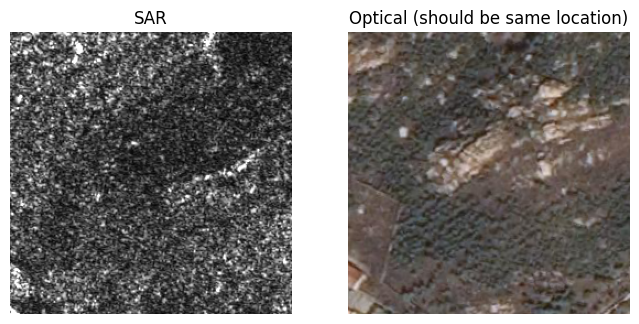

TEST_MODE OFF -- using full dataset (20000 pairs)


In [9]:

import shutil, random

# ---- STEP 1: point at wherever the QXS-SAROPT dataset actually extracted to ----
QXS_ROOT = PROJECT_ROOT / "QXS-SAROPT" / "QXSLAB_SAROPT"   # verify against the tree print above; adjust if it nests differently
SRC_SAR = QXS_ROOT / "sar_256_oc_0.2"      # check the actual folder name with `!ls {QXS_ROOT}` if this doesn't match
SRC_OPT = QXS_ROOT / "opt_256_oc_0.2"

RAW_SAR_DIR = PROJECT_ROOT / "dataset_full" / "SAR"
RAW_OPT_DIR = PROJECT_ROOT / "dataset_full" / "optical"
RAW_SAR_DIR.mkdir(parents=True, exist_ok=True)
RAW_OPT_DIR.mkdir(parents=True, exist_ok=True)

# ---- STEP 2: restructure -> same-stem paired files ----
# resume-safe: if a previous run already restructured the full dataset, skip re-copying
# everything (this is the whole dataset, so redoing it on every resume is slow and pointless).
sar_src_count = len(list(SRC_SAR.glob("*.png"))) + len(list(SRC_SAR.glob("*.jpg")))
raw_sar_count = len(list(RAW_SAR_DIR.glob("*.png")))

if sar_src_count > 0 and raw_sar_count >= sar_src_count:
    print(f"Found {raw_sar_count} pairs already restructured in {RAW_SAR_DIR} -- skipping re-copy.")
    matched, unmatched = raw_sar_count, None
else:
    sar_files = sorted(SRC_SAR.glob("*.png")) + sorted(SRC_SAR.glob("*.jpg"))
    matched, unmatched = 0, 0

    for sar_path in sar_files:
        stem = sar_path.stem
        dst_sar = RAW_SAR_DIR / (stem + ".png")
        dst_opt = RAW_OPT_DIR / (stem + ".png")
        if dst_sar.exists() and dst_opt.exists():
            matched += 1
            continue
        opt_path = SRC_OPT / (stem + ".png")
        if not opt_path.exists():
            opt_path = SRC_OPT / (stem + ".jpg")
        if not opt_path.exists():
            unmatched += 1
            continue
        shutil.copy(sar_path, dst_sar)
        shutil.copy(opt_path, dst_opt)
        matched += 1

    print(f"Matched pairs: {matched}, unmatched: {unmatched}")

# ---- STEP 3: sanity check -- verify one pair visually ----
sample_stem = sorted(RAW_SAR_DIR.glob("*.png"))[0].stem
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(Image.open(RAW_SAR_DIR / f"{sample_stem}.png"), cmap="gray"); ax[0].set_title("SAR"); ax[0].axis("off")
ax[1].imshow(Image.open(RAW_OPT_DIR / f"{sample_stem}.png")); ax[1].set_title("Optical (should be same location)"); ax[1].axis("off")
plt.show()

# ---- STEP 4: build the test subset ----
TEST_MODE = False         # <-- H100 full-dataset run (pipeline already verified on 500-image subset)
TEST_SUBSET_SIZE = 500

if TEST_MODE:
    subset_sar_dir = PROJECT_ROOT / "dataset_subset" / "SAR"
    subset_opt_dir = PROJECT_ROOT / "dataset_subset" / "optical"
    subset_sar_dir.mkdir(parents=True, exist_ok=True)
    subset_opt_dir.mkdir(parents=True, exist_ok=True)

    all_stems = [p.stem for p in RAW_SAR_DIR.glob("*.png")]
    random.seed(SEED)
    chosen = random.sample(all_stems, min(TEST_SUBSET_SIZE, len(all_stems)))

    for stem in chosen:
        shutil.copy(RAW_SAR_DIR / f"{stem}.png", subset_sar_dir / f"{stem}.png")
        shutil.copy(RAW_OPT_DIR / f"{stem}.png", subset_opt_dir / f"{stem}.png")

    # ---- overwrites the Setup cell's SAR_DIR / OPTICAL_DIR -- both absolute, both static ----
    SAR_DIR = subset_sar_dir
    OPTICAL_DIR = subset_opt_dir
    print(f"TEST_MODE ON -- using {len(chosen)} pairs from {subset_sar_dir.parent}")
else:
    SAR_DIR = RAW_SAR_DIR
    OPTICAL_DIR = RAW_OPT_DIR
    print(f"TEST_MODE OFF -- using full dataset ({len(list(RAW_SAR_DIR.glob('*.png')))} pairs)")


## Dataset loader (SAR + optical + mask)

In [10]:
class SAROpticalMaskDataset(Dataset):
    def __init__(self, sar_dir, optical_dir, mask_dir, img_size=IMG_SIZE, augment=True):
        self.sar_files = sorted(list(Path(sar_dir).glob("*.png")) + list(Path(sar_dir).glob("*.jpg")))
        self.optical_dir = Path(optical_dir)
        self.mask_dir = Path(mask_dir)
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.sar_files)

    def __getitem__(self, idx):
        sar_path = self.sar_files[idx]
        stem = sar_path.stem
        opt_path = self.optical_dir / (stem + ".png")
        if not opt_path.exists():
            opt_path = self.optical_dir / (stem + ".jpg")
        mask_path = self.mask_dir / (stem + ".png")

        sar = Image.open(sar_path).convert("L").resize((self.img_size, self.img_size))
        opt = Image.open(opt_path).convert("RGB").resize((self.img_size, self.img_size))
        mask = Image.open(mask_path).resize((self.img_size, self.img_size), Image.NEAREST) if mask_path.exists() \
               else Image.new("L", (self.img_size, self.img_size), 0)

        if self.augment and random.random() > 0.5:
            sar = sar.transpose(Image.FLIP_LEFT_RIGHT)
            opt = opt.transpose(Image.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.FLIP_LEFT_RIGHT)

        sar_t = torch.from_numpy(np.array(sar, dtype=np.float32) / 127.5 - 1.0).unsqueeze(0)
        opt_t = torch.from_numpy(np.array(opt, dtype=np.float32) / 127.5 - 1.0).permute(2, 0, 1)
        mask_t = torch.from_numpy(np.array(mask, dtype=np.int64))

        return sar_t, opt_t, mask_t


## Mask generation -- SegEarth-OV

**Install Miniconda + `segearth` Python 3.9 env**

In [11]:

import os
import subprocess

CONDA = "/usr/local/miniconda/bin/conda"
CONDA_PREFIX = "/usr/local/miniconda"
SEGEARTH_ENV_PY  = f"{CONDA_PREFIX}/envs/segearth/bin/python"
SEGEARTH_ENV_PIP = f"{CONDA_PREFIX}/envs/segearth/bin/pip"

def run(cmd):
    print(f"\n>>> {cmd}")
    result = subprocess.run(
        cmd, shell=True, executable="/bin/bash",
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    print(result.stdout)
    if result.returncode != 0:
        raise RuntimeError(f"Failed:\n{result.stdout}")

# Install Miniconda if missing (no-op if the LAE-DINO stage already did this)
if not os.path.exists(CONDA):
    run(f"""
    wget -q https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh -O /tmp/miniconda.sh
    bash /tmp/miniconda.sh -b -p {CONDA_PREFIX}
    """)
    run(f"{CONDA} tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main")
    run(f"{CONDA} tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r")

# Remove old env if it exists, then create fresh
subprocess.run(f"{CONDA} env remove -n segearth -y", shell=True,
               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
run(f"{CONDA} create -n segearth python=3.9 -y")
run(f"{SEGEARTH_ENV_PY} --version")

print("\n✅ Environment 'segearth' created successfully.")
print("SEGEARTH_ENV_PY :", SEGEARTH_ENV_PY)
print("SEGEARTH_ENV_PIP:", SEGEARTH_ENV_PIP)



>>> /usr/local/miniconda/bin/conda create -n segearth python=3.9 -y


KeyboardInterrupt: 

**Clone SegEarth-OV + install pinned stack (torch 2.1.2, mmcv 2.1.0, mmseg 1.2.2)**

In [11]:
import os

if not SEGEARTH_ROOT.exists():
    !git clone https://github.com/likyoo/SegEarth-OV.git {SEGEARTH_ROOT}
else:
    print(f"{SEGEARTH_ROOT} already exists -- skipping clone.")

os.chdir(SEGEARTH_ROOT)
print("cwd:", os.getcwd())

# 1) torch first, matching this runtime's CUDA (H100 -> CUDA 12.x -> cu121 wheels work).
!{SEGEARTH_ENV_PIP} install -q torch==2.1.2 torchvision==0.16.2 --index-url https://download.pytorch.org/whl/cu121

# 2) rest of requirements.txt, EXCLUDING mmcv/mmengine/mmsegmentation -- those need
#    to go through mim, and only AFTER torch is present (that's what broke before).
!grep -viE '^(mmcv|mmengine|mmsegmentation)' requirements.txt > /tmp/segearth_reqs_no_mm.txt
!{SEGEARTH_ENV_PIP} install -q -r /tmp/segearth_reqs_no_mm.txt

# 3) now mim can actually `import torch` to pick a matching mmcv wheel.
!{SEGEARTH_ENV_PIP} install -q -U openmim
!{SEGEARTH_ENV_PY} -m mim install -q mmengine
!{SEGEARTH_ENV_PY} -m mim install -q mmcv==2.1.0
!{SEGEARTH_ENV_PIP} install -q mmsegmentation==1.2.2

# numpy 2.x got pulled in somewhere in the mm* chain -- torch/opencv here were built
# against the numpy 1.x ABI, so force it back down, and do this LAST so nothing re-upgrades it.
!{SEGEARTH_ENV_PIP} install -q "numpy<2"

print("Done -- verifying:")
!{SEGEARTH_ENV_PY} -c "import numpy; print('numpy', numpy.__version__)"
!{SEGEARTH_ENV_PY} -c "import torch; print('torch', torch.__version__, 'cuda', torch.cuda.is_available())"
!{SEGEARTH_ENV_PY} -c "import cv2; print('cv2', cv2.__version__)"
!{SEGEARTH_ENV_PY} -c "import mmcv, mmseg; print('mmcv', mmcv.__version__, 'mmseg', mmseg.__version__)"

print("Done -- verifying:")
!{SEGEARTH_ENV_PY} -c "import torch, mmcv, mmseg; print('torch', torch.__version__, 'cuda', torch.cuda.is_available()); print('mmcv', mmcv.__version__); print('mmseg', mmseg.__version__)"

Cloning into '/home/seg_cyclegan_project/SegEarth-OV'...
remote: Enumerating objects: 314, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 314 (delta 23), reused 15 (delta 15), pack-reused 286 (from 1)
Receiving objects: 100% (314/314), 44.43 MiB | 28.74 MiB/s, done.
Resolving deltas: 100% (124/124), done.
cwd: /home/seg_cyclegan_project/SegEarth-OV

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/usr/local/miniconda/envs/segearth/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    retu

**Download SimFeatUp checkpoint (xclip_jbu_one_million_aid.ckpt)**

In [12]:

SIMFEATUP_WEIGHTS_DIR = SEGEARTH_ROOT / "simfeatup_dev" / "weights"
SIMFEATUP_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
SIMFEATUP_CKPT = SIMFEATUP_WEIGHTS_DIR / "xclip_jbu_one_million_aid.ckpt"

if not SIMFEATUP_CKPT.exists():
    !{SEGEARTH_ENV_PIP} install -q huggingface_hub

    # Written to a real script file rather than a one-line `-c` command -- multi-line
    # `-c` invocations are fragile once curly braces (f-strings) and Colab's own
    # `!{var}` substitution both want to touch the same line.
    download_script = f"""
from huggingface_hub import hf_hub_download
import shutil
p = hf_hub_download(
    repo_id="BiliSakura/AlignEarth-SAR-ViT-B-16",
    filename="simfeatup/xclip_jbu_one_million_aid.ckpt",
)
shutil.copy(p, r"{SIMFEATUP_CKPT}")
print("Copied SimFeatUp checkpoint to", r"{SIMFEATUP_CKPT}")
"""
    DOWNLOAD_SCRIPT_PATH = SEGEARTH_ROOT / "download_simfeatup_ckpt.py"
    with open(DOWNLOAD_SCRIPT_PATH, "w") as f:
        f.write(download_script)
    !{SEGEARTH_ENV_PY} {DOWNLOAD_SCRIPT_PATH}
else:
    print(f"SimFeatUp checkpoint already present at {SIMFEATUP_CKPT}, skipping download.")

print("Checkpoint size:")
!ls -lh {SIMFEATUP_CKPT}
print()
print("NOTE: if this HF mirror ever moves, the canonical source is the checkpoint")
print("demo.py in https://github.com/likyoo/SegEarth-OV loads by default -- check")
print("that repo's README / simfeatup_dev folder for an updated link.")


SimFeatUp checkpoint already present at /home/seg_cyclegan_project/SegEarth-OV/simfeatup_dev/weights/xclip_jbu_one_million_aid.ckpt, skipping download.
Checkpoint size:
-rw-r--r-- 1 root root 5.5M Aug  1 06:05 /home/seg_cyclegan_project/SegEarth-OV/simfeatup_dev/weights/xclip_jbu_one_million_aid.ckpt

NOTE: if this HF mirror ever moves, the canonical source is the checkpoint
demo.py in https://github.com/likyoo/SegEarth-OV loads by default -- check
that repo's README / simfeatup_dev folder for an updated link.


**Write class-name file for SegEarth-OV**

In [13]:

NAME_LIST = ["background"] + CLASS_QUERIES
NAME_PATH = SEGEARTH_ROOT / "configs" / "my_name.txt"
NAME_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(NAME_PATH, "w") as f:
    f.write("\n".join(NAME_LIST))
print(f"Wrote {len(NAME_LIST)} class names to {NAME_PATH}:")
print(NAME_LIST)


Wrote 9 class names to /home/seg_cyclegan_project/SegEarth-OV/configs/my_name.txt:
['background', 'water, lake, stream, river', 'ship, boat, vessel', 'building, house, home, residential building', 'road, street, highway', 'vegetation, trees, grass, forest', 'bare soil, bare land, barren land', 'parking lot, parking area, car park', 'dock, pier, harbor, port']


**Write SegEarth-OV inference script**

In [14]:

run_segearth_script = r'''
import sys, glob, argparse
sys.path.insert(0, ".")   # so `from segearth_segmentor import SegEarthSegmentation` resolves from SEGEARTH_ROOT
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
from segearth_segmentor import SegEarthSegmentation

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--img_dir", required=True)
    ap.add_argument("--out_dir", required=True)
    ap.add_argument("--name_path", required=True)
    ap.add_argument("--simfeatup_ckpt", required=True)
    ap.add_argument("--img_size", type=int, default=256)
    args = ap.parse_args()

    model = SegEarthSegmentation(
        clip_type="CLIP",
        vit_type="ViT-B/16",
        model_type="SegEarth",
        ignore_residual=True,
        feature_up=True,
        feature_up_cfg=dict(model_name="jbu_one", model_path=args.simfeatup_ckpt),
        cls_token_lambda=-0.3,
        name_path=args.name_path,
        prob_thd=0.1,
    )

    preprocess = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([0.48145466, 0.4578275, 0.40821073],
                              [0.26862954, 0.26130258, 0.27577711]),
        transforms.Resize((448, 448)),
    ])

    img_files = sorted(glob.glob(f"{args.img_dir}/*.png")) + sorted(glob.glob(f"{args.img_dir}/*.jpg"))
    print(f"Found {len(img_files)} images.")

    from pathlib import Path
    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    for img_path in img_files:
        stem = Path(img_path).stem
        out_path = out_dir / f"{stem}.png"
        if out_path.exists():
            continue
        img = Image.open(img_path).convert("RGB")
        img_tensor = preprocess(img).unsqueeze(0).to("cuda")
        with torch.no_grad():
            seg_pred = model.predict(img_tensor, data_samples=None)
        seg_pred = seg_pred.data.cpu().numpy().squeeze(0).astype(np.uint8)   # (448, 448) class-index map
        mask_img = Image.fromarray(seg_pred, mode="L").resize(
            (args.img_size, args.img_size), Image.NEAREST   # NEAREST -- keeps class indices exact, no blur
        )
        mask_img.save(out_path)

    print("Done.")

if __name__ == "__main__":
    main()
'''

RUN_SEGEARTH_SCRIPT_PATH = SEGEARTH_ROOT / "run_segearth.py"
clean_duplicate_files("run_segearth.py", keep_dir=SEGEARTH_ROOT)
with open(RUN_SEGEARTH_SCRIPT_PATH, "w") as f:
    f.write(run_segearth_script)
print("Wrote", RUN_SEGEARTH_SCRIPT_PATH)


No stray copies of run_segearth.py found outside /home/seg_cyclegan_project/SegEarth-OV.
Wrote /home/seg_cyclegan_project/SegEarth-OV/run_segearth.py


**Install FeatUp (AdaptiveConv op)**

In [15]:
import os, subprocess, sys

os.chdir(SEGEARTH_ROOT)  # keep cwd consistent with the rest of the SegEarth-OV cells

# ---- 1) ninja is required to compile FeatUp's CUDA + C++ extensions ----
!{SEGEARTH_ENV_PIP} install -q ninja

# ---- 2) point at this runtime's system CUDA toolkit, which has nvcc -- the env's own torch
#         install only ships the CUDA *runtime*, not the compiler ----
os.environ["CUDA_HOME"] = "/usr/local/cuda"

# Sanity check: nvcc's CUDA version vs. the CUDA version torch was built against --
# a mismatch here is the most common reason this extension silently fails to build.
print("---- CUDA version check ----")
!nvcc --version | tail -4
!{SEGEARTH_ENV_PY} -c "import torch; print('torch built for CUDA:', torch.version.cuda)"
print("(a minor mismatch, e.g. 12.1 vs 12.2, is usually fine -- a major one, e.g. 11.x vs 12.x, is not.)")

# ---- 3) clone FeatUp -- ships the actual AdaptiveConv CUDA/C++ extension source that
#         SegEarth-OV's simfeatup_dev/upsamplers.py imports but doesn't itself include ----
if not FEATUP_ROOT.exists():
    !git clone https://github.com/mhamilton723/FeatUp.git {FEATUP_ROOT}
else:
    print(f"{FEATUP_ROOT} already exists -- skipping clone.")

# ---- 4) build + install it: --no-build-isolation so it builds against THIS env's already-
#         installed torch/CUDA (not a fresh isolated one), -v for full compiler output so any
#         real error shows up here instead of being swallowed by pip's default quiet mode ----
featup_install_script = r"""
import os, subprocess, sys
os.environ["CUDA_HOME"] = "/usr/local/cuda"
os.chdir(r"FEATUP_ROOT_PLACEHOLDER")
result = subprocess.run(
    [sys.executable, "-m", "pip", "install", ".", "--no-build-isolation", "-v"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
print(result.stdout)
print("RETURN CODE:", result.returncode)
"""
featup_install_script = featup_install_script.replace("FEATUP_ROOT_PLACEHOLDER", str(FEATUP_ROOT))
with open("/tmp/install_featup.py", "w") as f:
    f.write(featup_install_script)

!{SEGEARTH_ENV_PY} /tmp/install_featup.py

# verify
!{SEGEARTH_ENV_PY} -c "from featup.adaptive_conv_cuda.adaptive_conv import AdaptiveConv; print('AdaptiveConv OK:', AdaptiveConv)"

!{SEGEARTH_ENV_PY} /tmp/install_featup.py

# ---- 5) verify: this must print a real class, not None, or the inference cell below
#         will hit the same AttributeError as before ----
!{SEGEARTH_ENV_PY} -c "from featup.adaptive_conv_cuda.adaptive_conv import AdaptiveConv; print('AdaptiveConv OK:', AdaptiveConv)"


---- CUDA version check ----
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Thu_Sep_12_02:18:05_PDT_2024
Cuda compilation tools, release 12.6, V12.6.77
Build cuda_12.6.r12.6/compiler.34841621_0
torch built for CUDA: 12.1
(a minor mismatch, e.g. 12.1 vs 12.2, is usually fine -- a major one, e.g. 11.x vs 12.x, is not.)
Cloning into '/home/seg_cyclegan_project/FeatUp'...
remote: Enumerating objects: 357, done.
remote: Counting objects: 100% (163/163), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 357 (delta 127), reused 115 (delta 115), pack-reused 194 (from 1)
Receiving objects: 100% (357/357), 39.05 MiB | 28.91 MiB/s, done.
Resolving deltas: 100% (193/193), done.
Using pip 26.0.1 from /usr/local/miniconda/envs/segearth/lib/python3.9/site-packages/pip (python 3.9)
Processing ./.
  Preparing metadata (pyproject.toml): started
  Running command Preparing metadata (pyproject.toml)
  running dist_info
  creating /tmp/pip-modern-metadata-wzr8_7mo/featup.egg-info
  

**Run SegEarth-OV inference -> masks**

In [13]:
import os, json as _json
os.chdir(SEGEARTH_ROOT)

# ---- class-scheme change detection --------------------------------------------------
# run_segearth.py skips any output file that already exists, so if CLASS_NAMES/NUM_CLASSES
# changed since masks were last generated, stale masks from the OLD scheme would silently
# survive and never get regenerated. Guard against that with a small marker file recording
# which class scheme produced the masks currently in MASK_DIR.
CLASS_CONFIG_MARKER = MASK_DIR / "_class_config.json"
current_class_config = {"NUM_CLASSES": NUM_CLASSES, "CLASS_NAMES": CLASS_NAMES}

if CLASS_CONFIG_MARKER.exists():
    with open(CLASS_CONFIG_MARKER) as f:
        saved_class_config = _json.load(f)
    stale = saved_class_config != current_class_config
    if stale:
        print(f"Class scheme changed since these masks were generated "
              f"(had {saved_class_config.get('NUM_CLASSES')} classes: {saved_class_config.get('CLASS_NAMES')}; "
              f"now {NUM_CLASSES} classes: {CLASS_NAMES}) -- clearing {MASK_DIR} so masks regenerate "
              f"under the current scheme.")
        for f in MASK_DIR.glob("*.png"):
            f.unlink()
elif any(MASK_DIR.glob("*.png")):
    # masks exist but no marker (e.g. generated before this check existed) -- can't verify
    # they match the current scheme, so clear them to regenerate safely rather than risk
    # silently training against masks with a different, unknown class layout.
    print(f"Found masks in {MASK_DIR} with no recorded class scheme -- clearing them to "
          f"regenerate safely under the current {NUM_CLASSES}-class scheme.")
    for f in MASK_DIR.glob("*.png"):
        f.unlink()
    stale = True
else:
    stale = False

# ---- resume-safe: don't regenerate masks that already exist on disk from a previous run ----
existing_masks = len(list(MASK_DIR.glob("*.png")))
expected_masks = len(list(OPTICAL_DIR.glob("*.png")))

if SKIP_MASK_GENERATION:
    print("Skipped (SKIP_MASK_GENERATION=True)")
elif not stale and expected_masks > 0 and existing_masks >= expected_masks:
    print(f"Found {existing_masks}/{expected_masks} masks already in {MASK_DIR} -- skipping regeneration. "
          f"(Delete files in MASK_DIR if you want to force a re-run.)")
else:
    !{SEGEARTH_ENV_PY} {RUN_SEGEARTH_SCRIPT_PATH} \
      --img_dir "{OPTICAL_DIR}" \
      --out_dir "{MASK_DIR}" \
      --name_path "{NAME_PATH}" \
      --simfeatup_ckpt "{SIMFEATUP_CKPT}" \
      --img_size {IMG_SIZE}

    with open(CLASS_CONFIG_MARKER, "w") as f:
        _json.dump(current_class_config, f, indent=2)
    print(f"Recorded current class scheme to {CLASS_CONFIG_MARKER}")


Found 20000/20000 masks already in /home/seg_cyclegan_project/dataset/mask -- skipping regeneration. (Delete files in MASK_DIR if you want to force a re-run.)


## Spot-check generated masks

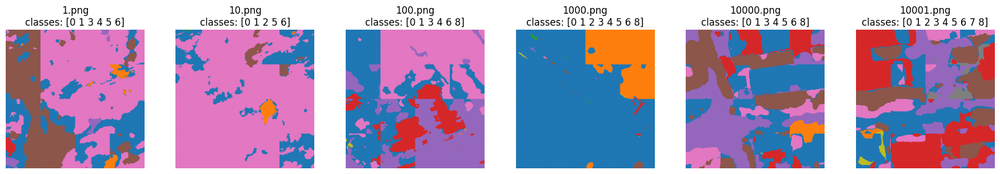

In [14]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

mask_files = sorted(MASK_DIR.glob("*.png"))[:6]
fig, axes = plt.subplots(1, len(mask_files), figsize=(18, 3))
for ax, mp in zip(axes, mask_files):
    m = np.array(Image.open(mp))
    ax.imshow(m, cmap="tab10", vmin=0, vmax=NUM_CLASSES)
    ax.set_title(f"{mp.name}\nclasses: {np.unique(m)}")
    ax.axis("off")
plt.tight_layout()
plt.show()


In [19]:

from collections import Counter
class_presence = Counter()
for mp in MASK_DIR.glob("*.png"):
    m = np.array(Image.open(mp))
    for c in np.unique(m):
        class_presence[int(c)] += 1
print("SegEarth-OV class presence (# images containing each class idx):")
print(class_presence)


SegEarth-OV class presence (# images containing each class idx):
Counter({0: 19496, 5: 19068, 4: 18870, 6: 17298, 3: 15648, 1: 12365, 8: 9618, 7: 7662, 2: 7404})


In [ ]:
# import torch

# print("CUDA Available:", torch.cuda.is_available())
# print("GPU Count:", torch.cuda.device_count())

# if torch.cuda.is_available():
#     print("GPU Name:", torch.cuda.get_device_name(0))
#     print("CUDA Version:", torch.version.cuda)
# else:
#     print("❌ No GPU is connected.")

## SegFormer training

In [15]:
import json as _json

class SegFormerSegmenter(nn.Module):
    # SegFormer (MiT-B2, ImageNet-pretrained encoder) as SAR/fake-optical -> class-mask segmenter.
    # Input stays 1-channel (SAR, or fake-optical averaged to grayscale) in [-1, 1] -- this wrapper
    # adapts it to the 3-channel, ImageNet-normalized input SegFormer expects, and upsamples its
    # (H/4, W/4) logits back to full resolution: same call signature as before, same output shape
    # [B, num_classes, H, W], gradients still flow through into G_AB.
    def __init__(self, num_classes=NUM_CLASSES, pretrained="nvidia/mit-b2"):
        super().__init__()
        from transformers import SegformerForSemanticSegmentation
        self.model = SegformerForSemanticSegmentation.from_pretrained(
            pretrained, num_labels=num_classes, ignore_mismatched_sizes=True
        )
        self.register_buffer("imagenet_mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("imagenet_std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        H, W = x.shape[-2:]
        x3 = x.repeat(1, 3, 1, 1)
        x3 = (x3 + 1) / 2
        x3 = (x3 - self.imagenet_mean) / self.imagenet_std
        logits = self.model(pixel_values=x3).logits
        logits = F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
        return logits


def compute_class_weights(mask_dir, num_classes):
    counts = np.zeros(num_classes, dtype=np.int64)
    for mp in Path(mask_dir).glob("*.png"):
        m = np.array(Image.open(mp))
        for c in range(num_classes):
            counts[c] += (m == c).sum()
    counts = np.clip(counts, 1, None)
    return torch.tensor(counts.sum() / (num_classes * counts), dtype=torch.float32)


@torch.no_grad()
def per_class_iou(pred, target, num_classes):
    ious = np.full(num_classes, np.nan)
    pred = pred.reshape(-1); target = target.reshape(-1)
    for c in range(num_classes):
        pred_c = (pred == c); target_c = (target == c)
        union = (pred_c | target_c).sum().item()
        if union == 0:
            continue
        inter = (pred_c & target_c).sum().item()
        ious[c] = inter / union
    return ious


# ---- checkpoint paths: SEG_BEST_PATH is the weights-only file every downstream cell loads;
#      SEG_CKPT_LATEST carries full training state (optimizer/scheduler/epoch) so a paused
#      instance can resume mid-training instead of restarting SegFormer from epoch 0. ----
SEG_BEST_PATH = CKPT_DIR / "sar_segmenter.pth"
SEG_CKPT_LATEST = CKPT_DIR / "sar_segmenter_latest.pth"
SEG_CLASS_CONFIG_MARKER = CKPT_DIR / "sar_segmenter_class_config.json"

# ---- class-scheme change detection -------------------------------------------------------
# SEG_BEST_PATH/SEG_CKPT_LATEST are sized to NUM_CLASSES -- if CLASS_NAMES changed since they
# were saved (e.g. classes added/removed), loading them would crash on a shape mismatch (or
# silently produce garbage predictions if shapes happened to still line up). Detect that here
# and clear the stale checkpoints instead of letting the load below blow up.
current_class_config = {"NUM_CLASSES": NUM_CLASSES, "CLASS_NAMES": CLASS_NAMES}
existing_seg_ckpts = [p for p in (SEG_BEST_PATH, SEG_CKPT_LATEST) if p.exists()]

if existing_seg_ckpts:
    if SEG_CLASS_CONFIG_MARKER.exists():
        with open(SEG_CLASS_CONFIG_MARKER) as f:
            saved_class_config = _json.load(f)
        segmenter_stale = saved_class_config != current_class_config
    else:
        # checkpoint(s) exist but no record of what class scheme made them -- can't verify,
        # so treat as stale rather than risk silently loading a mismatched segmenter.
        saved_class_config = None
        segmenter_stale = True

    if segmenter_stale:
        print(f"Segmenter checkpoint(s) don't match the current class scheme "
              f"(had {saved_class_config.get('NUM_CLASSES') if saved_class_config else '?'} classes"
              f"{': ' + str(saved_class_config.get('CLASS_NAMES')) if saved_class_config else ''}; "
              f"now {NUM_CLASSES} classes: {CLASS_NAMES}) -- removing them so training starts fresh "
              f"under the current scheme.")
        for p in existing_seg_ckpts:
            p.unlink()
        if SKIP_SEGMENTER_TRAINING:
            print("NOTE: SKIP_SEGMENTER_TRAINING was True, but forcing training since no valid "
                  "checkpoint exists for the current class scheme.")
            SKIP_SEGMENTER_TRAINING = False

if not SKIP_SEGMENTER_TRAINING:
    class_weights = compute_class_weights(MASK_DIR, NUM_CLASSES).to(DEVICE)
    seg_full_ds = SAROpticalMaskDataset(SAR_DIR, OPTICAL_DIR, MASK_DIR, augment=True)
    val_size = int(0.1 * len(seg_full_ds)); train_size = len(seg_full_ds) - val_size
    seg_train_ds, seg_val_ds = torch.utils.data.random_split(seg_full_ds, [train_size, val_size])
    seg_train_loader = DataLoader(seg_train_ds, batch_size=32, shuffle=True, num_workers=8)   # H100: bumped from 16/2
    seg_val_loader = DataLoader(seg_val_ds, batch_size=32, shuffle=False, num_workers=8)

    segmenter = SegFormerSegmenter().to(DEVICE)

    encoder_params = segmenter.model.segformer.parameters()
    decoder_params = segmenter.model.decode_head.parameters()
    seg_optimizer = torch.optim.AdamW([
        {"params": encoder_params, "lr": 1e-5, "weight_decay": 1e-4},
        {"params": decoder_params, "lr": 1e-4, "weight_decay": 1e-4},
    ])
    SEG_EPOCHS = 30
    seg_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(seg_optimizer, T_max=SEG_EPOCHS)
    seg_criterion = nn.CrossEntropyLoss(weight=class_weights)

    PATIENCE = 7
    best_val_loss = float("inf")
    patience_counter = 0
    seg_start_epoch = 0

    # ---- W&B: one run per segmenter, reused across resumes via a saved run id ----
    seg_wandb_run_id, seg_wandb_id_path = get_or_create_wandb_run_id("segformer")
    seg_wandb_run = wandb.init(
        project=WANDB_PROJECT, entity=WANDB_ENTITY, name="segformer-segmenter",
        id=seg_wandb_run_id, resume="allow", job_type="train-segmenter",
        config={
            "SEG_EPOCHS": SEG_EPOCHS, "PATIENCE": PATIENCE, "NUM_CLASSES": NUM_CLASSES,
            "CLASS_NAMES": CLASS_NAMES, "encoder_lr": 1e-5, "decoder_lr": 1e-4,
            "batch_size": 32, "pretrained": "nvidia/mit-b2",
        },
    )
    if seg_wandb_run_id is None:
        seg_wandb_id_path.write_text(seg_wandb_run.id)

    # ---- resume-safe: pick up mid-training if a previous run was paused/destroyed and restarted ----
    if SEG_CKPT_LATEST.exists():
        seg_ckpt = torch.load(SEG_CKPT_LATEST, map_location=DEVICE)
        segmenter.load_state_dict(seg_ckpt["model"])
        seg_optimizer.load_state_dict(seg_ckpt["optimizer"])
        seg_scheduler.load_state_dict(seg_ckpt["scheduler"])
        best_val_loss = seg_ckpt["best_val_loss"]
        patience_counter = seg_ckpt["patience_counter"]
        seg_start_epoch = seg_ckpt["epoch"] + 1
        print(f"Resuming SegFormer training from epoch {seg_start_epoch+1} "
              f"(best_val_loss so far={best_val_loss:.4f}, patience={patience_counter}/{PATIENCE}).")
    else:
        print("No SegFormer checkpoint found -- starting fresh from epoch 1.")

    # record which class scheme this training run belongs to, so future runs can detect drift
    with open(SEG_CLASS_CONFIG_MARKER, "w") as f:
        _json.dump(current_class_config, f, indent=2)

    if seg_start_epoch >= SEG_EPOCHS:
        print("SegFormer checkpoint already reached SEG_EPOCHS -- nothing left to train.")

    for epoch in range(seg_start_epoch, SEG_EPOCHS):
        segmenter.train(); train_loss = 0.0
        for sar, _, mask in tqdm(seg_train_loader, desc=f"SegFormer epoch {epoch+1}/{SEG_EPOCHS}"):
            sar, mask = sar.to(DEVICE), mask.to(DEVICE)
            seg_optimizer.zero_grad()
            loss = seg_criterion(segmenter(sar), mask)
            loss.backward(); seg_optimizer.step()
            train_loss += loss.item() * sar.size(0)
        train_loss /= len(seg_train_ds)

        segmenter.eval(); val_loss = 0.0
        iou_accum = np.zeros(NUM_CLASSES); iou_count = np.zeros(NUM_CLASSES)
        with torch.no_grad():
            for sar, _, mask in seg_val_loader:
                sar, mask = sar.to(DEVICE), mask.to(DEVICE)
                logits = segmenter(sar)
                val_loss += seg_criterion(logits, mask).item() * sar.size(0)
                pred = logits.argmax(dim=1)
                batch_ious = per_class_iou(pred, mask, NUM_CLASSES)
                valid = ~np.isnan(batch_ious)
                iou_accum[valid] += batch_ious[valid]; iou_count[valid] += 1
        val_loss /= len(seg_val_ds)
        seg_scheduler.step()

        mean_iou = np.nanmean(np.where(iou_count > 0, iou_accum / np.maximum(iou_count, 1), np.nan))
        per_class_str = ", ".join(
            f"c{c}={iou_accum[c]/iou_count[c]:.3f}" if iou_count[c] > 0 else f"c{c}=n/a"
            for c in range(NUM_CLASSES)
        )
        print(f"Epoch {epoch+1}: train={train_loss:.4f} val={val_loss:.4f} mIoU={mean_iou:.3f} | {per_class_str}")

        wandb_class_ious = {}
        for c in range(NUM_CLASSES):
            label = "background" if c == 0 else CLASS_NAMES[c - 1]
            wandb_class_ious[f"iou/{label}"] = (iou_accum[c] / iou_count[c]) if iou_count[c] > 0 else float("nan")
        wandb.log({
            "epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss, "mean_iou": mean_iou,
            "lr_encoder": seg_optimizer.param_groups[0]["lr"], "lr_decoder": seg_optimizer.param_groups[1]["lr"],
            **wandb_class_ious,
        }, step=epoch + 1)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save(segmenter.state_dict(), SEG_BEST_PATH)
            # ---- off-instance backup: upload the new best checkpoint to W&B ----
            seg_artifact = wandb.Artifact(
                "segformer-best", type="model",
                metadata={"epoch": epoch + 1, "val_loss": val_loss, "mean_iou": mean_iou,
                          "num_classes": NUM_CLASSES, "class_names": CLASS_NAMES},
            )
            seg_artifact.add_file(str(SEG_BEST_PATH))
            wandb.log_artifact(seg_artifact)
        else:
            patience_counter += 1

        # ---- save full training state every epoch -- a pause/resume picks up right after this epoch ----
        torch.save({
            "epoch": epoch,
            "model": segmenter.state_dict(),
            "optimizer": seg_optimizer.state_dict(),
            "scheduler": seg_scheduler.state_dict(),
            "best_val_loss": best_val_loss,
            "patience_counter": patience_counter,
        }, SEG_CKPT_LATEST)

        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (no val improvement for {PATIENCE} epochs).")
            break
    print("SegFormer training done. Best val_loss:", best_val_loss)
    wandb.finish()
else:
    print("Skipped (SKIP_SEGMENTER_TRAINING=True)")

segmenter = SegFormerSegmenter().to(DEVICE)
segmenter.load_state_dict(torch.load(SEG_BEST_PATH, map_location=DEVICE))
segmenter.eval()
for p in segmenter.parameters():
    p.requires_grad = False


KeyboardInterrupt: 

## Dual Generators (G_AB, G_BA) + Dual Discriminators (D_A, D_B)

In [17]:
class ResnetBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.block = nn.Sequential(
            nn.ReflectionPad2d(1), nn.Conv2d(dim, dim, 3), nn.InstanceNorm2d(dim), nn.ReLU(True),
            nn.ReflectionPad2d(1), nn.Conv2d(dim, dim, 3), nn.InstanceNorm2d(dim),
        )
    def forward(self, x):
        return x + self.block(x)


class ResnetGenerator(nn.Module):
    def __init__(self, in_ch, out_ch, ngf=64, n_blocks=9):
        super().__init__()
        model = [nn.ReflectionPad2d(3), nn.Conv2d(in_ch, ngf, 7), nn.InstanceNorm2d(ngf), nn.ReLU(True)]
        n_down = 2
        for i in range(n_down):
            mult = 2 ** i
            model += [nn.Conv2d(ngf * mult, ngf * mult * 2, 3, stride=2, padding=1),
                       nn.InstanceNorm2d(ngf * mult * 2), nn.ReLU(True)]
        mult = 2 ** n_down
        for _ in range(n_blocks):
            model += [ResnetBlock(ngf * mult)]
        for i in range(n_down):
            mult = 2 ** (n_down - i)
            model += [nn.ConvTranspose2d(ngf * mult, int(ngf * mult / 2), 3, stride=2, padding=1, output_padding=1),
                       nn.InstanceNorm2d(int(ngf * mult / 2)), nn.ReLU(True)]
        model += [nn.ReflectionPad2d(3), nn.Conv2d(ngf, out_ch, 7), nn.Tanh()]
        self.model = nn.Sequential(*model)

    def forward(self, x):
        return self.model(x)


class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch, ndf=64):
        super().__init__()
        layers = [nn.Conv2d(in_ch, ndf, 4, stride=2, padding=1), nn.LeakyReLU(0.2, True)]
        mult = 1
        for i in range(1, 3):
            prev_mult = mult; mult = min(2 ** i, 8)
            layers += [nn.Conv2d(ndf * prev_mult, ndf * mult, 4, stride=2, padding=1),
                       nn.InstanceNorm2d(ndf * mult), nn.LeakyReLU(0.2, True)]
        prev_mult = mult; mult = min(2 ** 3, 8)
        layers += [nn.Conv2d(ndf * prev_mult, ndf * mult, 4, stride=1, padding=1),
                   nn.InstanceNorm2d(ndf * mult), nn.LeakyReLU(0.2, True)]
        layers += [nn.Conv2d(ndf * mult, 1, 4, stride=1, padding=1)]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


G_AB = ResnetGenerator(in_ch=1, out_ch=3, ngf=64, n_blocks=9).to(DEVICE)   # SAR -> Optical
G_BA = ResnetGenerator(in_ch=3, out_ch=1, ngf=64, n_blocks=9).to(DEVICE)   # Optical -> SAR
D_A = PatchGANDiscriminator(in_ch=1, ndf=64).to(DEVICE)                    # judges SAR
D_B = PatchGANDiscriminator(in_ch=3, ndf=64).to(DEVICE)                    # judges Optical

print("G_AB params:", sum(p.numel() for p in G_AB.parameters()) / 1e6, "M")
print("D_B params:", sum(p.numel() for p in D_B.parameters()) / 1e6, "M")


G_AB params: 11.371907 M
D_B params: 2.764737 M


## Loss functions (CycleGAN + Seg-guided + Paired L1)

In [22]:
criterion_gan = nn.MSELoss()
criterion_cycle = nn.L1Loss()
criterion_seg = nn.CrossEntropyLoss()
criterion_pixel = nn.L1Loss()          # direct paired supervision (QXS-SAROPT is paired data)

LAMBDA_CYCLE = 10.0
LAMBDA_SEG = 1.0
LAMBDA_PIXEL = 10.0                    # start equal to lambda_cycle, tune later if colors look washed out
# identity loss removed -- SAR(1ch)/Optical(3ch) channel mismatch, not valid for cross-modal setup

def gan_loss(pred, target_is_real):
    target = torch.ones_like(pred) if target_is_real else torch.zeros_like(pred)
    return criterion_gan(pred, target)

def seg_guided_loss(fake_optical, real_sar, segmenter):
    fake_gray = fake_optical.mean(dim=1, keepdim=True)
    with torch.no_grad():
        target_mask = segmenter(real_sar).argmax(dim=1)
    pred_logits = segmenter(fake_gray)
    return criterion_seg(pred_logits, target_mask)


## Step-level debug view

In [23]:
def to_img(t):
    arr = t.detach().cpu().numpy()
    if arr.shape[0] == 1:
        arr = arr[0]
        cmap = "gray"
    else:
        arr = arr.transpose(1, 2, 0)
        cmap = None
    arr = ((arr + 1) * 127.5).clip(0, 255).astype(np.uint8)
    return arr, cmap


def debug_forward_pass(sar, real_opt, segmenter, step, save=True):
    G_AB.eval(); G_BA.eval(); D_A.eval(); D_B.eval()
    with torch.no_grad():
        fake_opt = G_AB(sar)
        d_b_score = D_B(fake_opt)
        recon_sar = G_BA(fake_opt)
        cycle_loss_a = criterion_cycle(recon_sar, sar).item()

        fake_sar = G_BA(real_opt)
        d_a_score = D_A(fake_sar)
        recon_opt = G_AB(fake_sar)
        cycle_loss_b = criterion_cycle(recon_opt, real_opt).item()

        fake_gray = fake_opt.mean(dim=1, keepdim=True)
        target_mask = segmenter(sar).argmax(dim=1)
        pred_mask = segmenter(fake_gray).argmax(dim=1)
        seg_loss = criterion_seg(segmenter(fake_gray), target_mask).item()

    fig, ax = plt.subplots(3, 3, figsize=(13, 13))
    im, cmap = to_img(sar[0]); ax[0,0].imshow(im, cmap=cmap); ax[0,0].set_title("1. Real SAR (input)"); ax[0,0].axis("off")
    im, cmap = to_img(fake_opt[0]); ax[0,1].imshow(im, cmap=cmap); ax[0,1].set_title("2. G_AB(SAR) -> fake optical"); ax[0,1].axis("off")
    ax[0,2].imshow(d_b_score[0,0].cpu().numpy(), cmap="RdYlGn"); ax[0,2].set_title("3. D_B patch-score\n(green=real-looking)"); ax[0,2].axis("off")

    im, cmap = to_img(recon_sar[0]); ax[1,0].imshow(im, cmap=cmap); ax[1,0].set_title(f"4. G_BA(fake_opt) cycle-back\ncycle_loss_A={cycle_loss_a:.3f}"); ax[1,0].axis("off")
    im, cmap = to_img(real_opt[0]); ax[1,1].imshow(im, cmap=cmap); ax[1,1].set_title("5. Real Optical (input)"); ax[1,1].axis("off")
    im, cmap = to_img(fake_sar[0]); ax[1,2].imshow(im, cmap=cmap); ax[1,2].set_title("6. G_BA(Optical) -> fake SAR"); ax[1,2].axis("off")

    im, cmap = to_img(recon_opt[0]); ax[2,0].imshow(im, cmap=cmap); ax[2,0].set_title(f"7. G_AB(fake_sar) cycle-back\ncycle_loss_B={cycle_loss_b:.3f}"); ax[2,0].axis("off")
    ax[2,1].imshow(d_a_score[0,0].cpu().numpy(), cmap="RdYlGn"); ax[2,1].set_title("8. D_A patch-score on fake_sar\n(green=real-looking)"); ax[2,1].axis("off")
    ax[2,2].imshow(pred_mask[0].cpu().numpy(), cmap="tab10", vmin=0, vmax=NUM_CLASSES)
    ax[2,2].set_title(f"9. SegFormer(fake_opt) mask\nseg_loss={seg_loss:.3f}"); ax[2,2].axis("off")

    plt.suptitle(f"Step {step} - full pipeline debug view", fontsize=14)
    plt.tight_layout()
    if save:
        plt.savefig(DEBUG_DIR / f"step_{step:06d}.png", dpi=100)
    plt.show()
    plt.close(fig)

    G_AB.train(); G_BA.train(); D_A.train(); D_B.train()
    return {"cycle_loss_A": cycle_loss_a, "cycle_loss_B": cycle_loss_b, "seg_loss": seg_loss}

## Training loop (H100: batch_size=16, num_workers=8)

Training config saved to: /home/seg_cyclegan_project/checkpoints/training_config.json
{
  "EPOCHS": 100,
  "DECAY_EPOCH": 75,
  "BATCH_SIZE": 16,
  "LR": 0.0002,
  "LAMBDA_CYCLE": 10.0,
  "LAMBDA_SEG": 1.0,
  "LAMBDA_PIXEL": 10.0,
  "IMG_SIZE": 256,
  "NUM_CLASSES": 9,
  "CLASS_NAMES": [
    "water",
    "ship",
    "building",
    "road",
    "vegetation",
    "bare soil",
    "parking lot",
    "dock"
  ],
  "TEST_SUBSET_SIZE": 500,
  "CHECKPOINT_EVERY_N_EPOCHS": 10
}


No existing checkpoint found -- starting fresh from epoch 1.


Epoch 1/100: 100%|█████████▉| 1249/1250 [06:57<00:00,  2.99it/s]

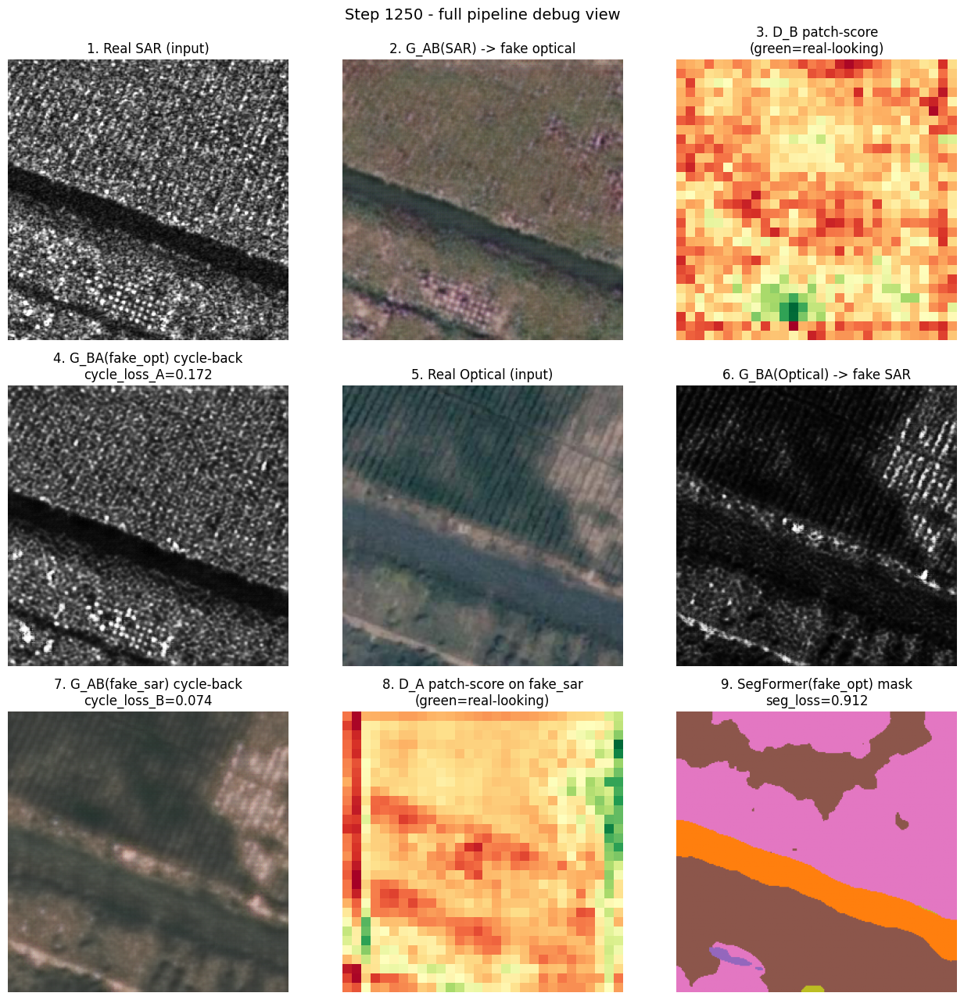

[Step 1250] G_total=7.602 D_A=0.263 D_B=0.114 pixel=3.259 | {'cycle_loss_A': 0.17167478799819946, 'cycle_loss_B': 0.07447808980941772, 'seg_loss': 0.911931037902832}


Epoch 1/100: 100%|██████████| 1250/1250 [06:59<00:00,  2.98it/s]


Epoch 1 avg: G=8.8994 D_A=0.2504 D_B=0.1455


Epoch 2/100: 100%|█████████▉| 1249/1250 [06:57<00:00,  2.99it/s]

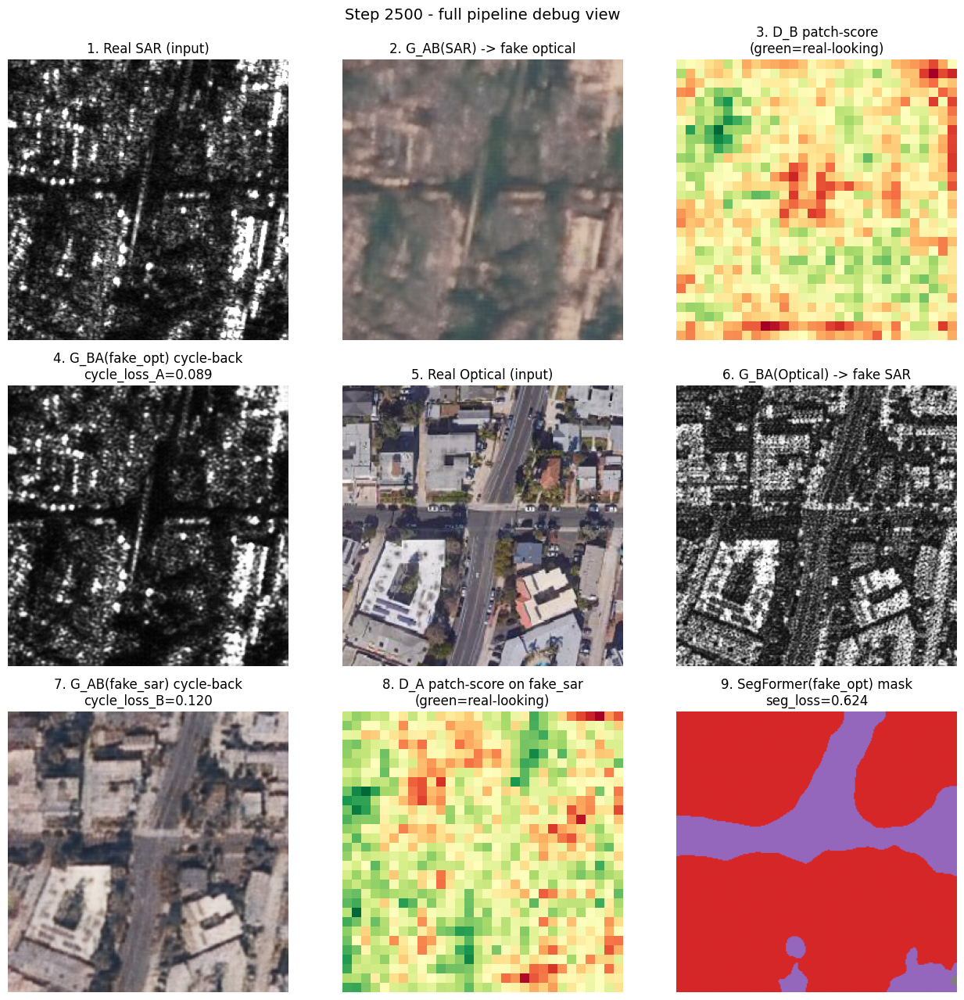

Epoch 2/100: 100%|██████████| 1250/1250 [06:59<00:00,  2.98it/s]


[Step 2500] G_total=7.266 D_A=0.192 D_B=0.113 pixel=2.924 | {'cycle_loss_A': 0.08854399621486664, 'cycle_loss_B': 0.11968167126178741, 'seg_loss': 0.6237953901290894}
Epoch 2 avg: G=7.9482 D_A=0.2184 D_B=0.1180


Epoch 3/100: 100%|█████████▉| 1249/1250 [06:57<00:00,  2.99it/s]

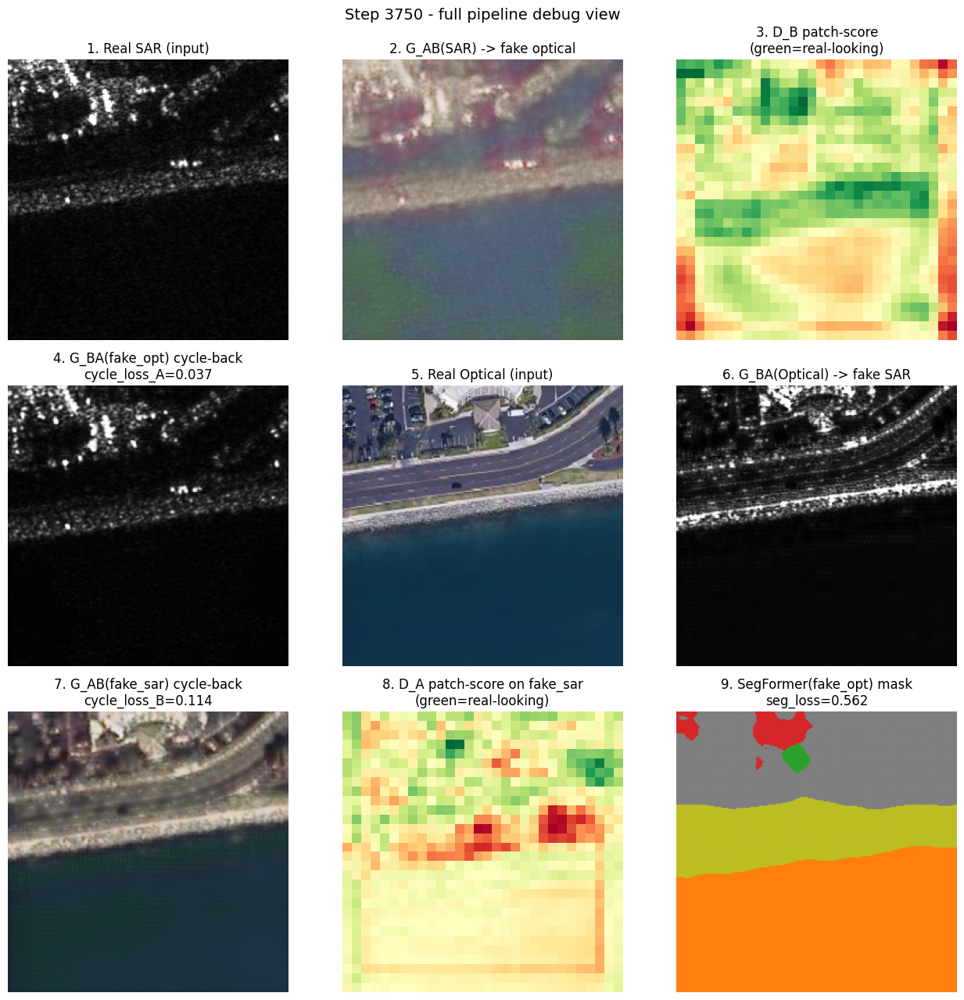

Epoch 3/100: 100%|██████████| 1250/1250 [06:59<00:00,  2.98it/s]


[Step 3750] G_total=6.692 D_A=0.162 D_B=0.169 pixel=2.992 | {'cycle_loss_A': 0.03699669614434242, 'cycle_loss_B': 0.11413553357124329, 'seg_loss': 0.562237560749054}
Epoch 3 avg: G=7.5852 D_A=0.2117 D_B=0.1272


Epoch 4/100:   0%|          | 5/1250 [00:01<07:18,  2.84it/s]

In [ ]:

# ---- checkpoints live on this Jarvis instance's local persistent disk, not Drive ----
# CKPT_DIR is defined in the Setup cell (PROJECT_ROOT / "checkpoints"); this fallback only
# exists in case this cell gets run in a fresh runtime where Setup wasn't re-run first.
if "CKPT_DIR" not in dir():
    PROJECT_ROOT = Path("/home/seg_cyclegan_project")
    CKPT_DIR = PROJECT_ROOT / "checkpoints"
    print(f"CKPT_DIR wasn't in scope -- re-derived it as {CKPT_DIR}. "
          f"If your workspace layout differs, re-run the Setup cell instead of relying on this fallback.")

CKPT_DIR.mkdir(parents=True, exist_ok=True)
LATEST_CKPT_PATH = CKPT_DIR / "cyclegan_checkpoint_latest.pth"
CONFIG_PATH_OUT = CKPT_DIR / "training_config.json"
CHECKPOINT_EVERY_N_EPOCHS = 10

EPOCHS = 100
DECAY_EPOCH = 75
BATCH_SIZE = 16   # H100: bumped from 4 (80GB VRAM headroom for ResNet-9blocks G + PatchGAN D at 256x256)
LR = 2e-4

# ---- save all hyperparameters to their own file, separate from the model weights ----
training_config = {
    "EPOCHS": EPOCHS,
    "DECAY_EPOCH": DECAY_EPOCH,
    "BATCH_SIZE": BATCH_SIZE,
    "LR": LR,
    "LAMBDA_CYCLE": LAMBDA_CYCLE,
    "LAMBDA_SEG": LAMBDA_SEG,
    "LAMBDA_PIXEL": LAMBDA_PIXEL,
    "IMG_SIZE": IMG_SIZE,
    "NUM_CLASSES": NUM_CLASSES,
    "CLASS_NAMES": CLASS_NAMES,
    "TEST_SUBSET_SIZE": TEST_SUBSET_SIZE if "TEST_SUBSET_SIZE" in dir() else None,
    "CHECKPOINT_EVERY_N_EPOCHS": CHECKPOINT_EVERY_N_EPOCHS,
}
with open(CONFIG_PATH_OUT, "w") as f:
    json.dump(training_config, f, indent=2)
print("Training config saved to:", CONFIG_PATH_OUT)
print(json.dumps(training_config, indent=2))

# ---- W&B: one run per CycleGAN training job, reused across resumes via a saved run id ----
cyclegan_wandb_run_id, cyclegan_wandb_id_path = get_or_create_wandb_run_id("cyclegan")
cyclegan_wandb_run = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY, name="cyclegan",
    id=cyclegan_wandb_run_id, resume="allow", job_type="train-cyclegan",
    config=training_config,
)
if cyclegan_wandb_run_id is None:
    cyclegan_wandb_id_path.write_text(cyclegan_wandb_run.id)

full_ds = SAROpticalMaskDataset(SAR_DIR, OPTICAL_DIR, MASK_DIR, augment=True)
train_loader = DataLoader(full_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=8, drop_last=True)   # H100: num_workers 4->8

opt_G = torch.optim.Adam(list(G_AB.parameters()) + list(G_BA.parameters()), lr=LR, betas=(0.5, 0.999))
opt_D_A = torch.optim.Adam(D_A.parameters(), lr=LR, betas=(0.5, 0.999))
opt_D_B = torch.optim.Adam(D_B.parameters(), lr=LR, betas=(0.5, 0.999))

def lr_lambda(epoch):
    if epoch < DECAY_EPOCH:
        return 1.0
    return max(0.0, 1.0 - (epoch - DECAY_EPOCH) / (EPOCHS - DECAY_EPOCH))

sched_G = torch.optim.lr_scheduler.LambdaLR(opt_G, lr_lambda)
sched_D_A = torch.optim.lr_scheduler.LambdaLR(opt_D_A, lr_lambda)
sched_D_B = torch.optim.lr_scheduler.LambdaLR(opt_D_B, lr_lambda)


def save_checkpoint(epoch, global_step, path):
    torch.save({
        "epoch": epoch,
        "global_step": global_step,
        "G_AB": G_AB.state_dict(),
        "G_BA": G_BA.state_dict(),
        "D_A": D_A.state_dict(),
        "D_B": D_B.state_dict(),
        "opt_G": opt_G.state_dict(),
        "opt_D_A": opt_D_A.state_dict(),
        "opt_D_B": opt_D_B.state_dict(),
        "sched_G": sched_G.state_dict(),
        "sched_D_A": sched_D_A.state_dict(),
        "sched_D_B": sched_D_B.state_dict(),
        "training_config": training_config,
    }, path)


def load_checkpoint(path):
    ckpt = torch.load(path, map_location=DEVICE)
    G_AB.load_state_dict(ckpt["G_AB"])
    G_BA.load_state_dict(ckpt["G_BA"])
    D_A.load_state_dict(ckpt["D_A"])
    D_B.load_state_dict(ckpt["D_B"])
    opt_G.load_state_dict(ckpt["opt_G"])
    opt_D_A.load_state_dict(ckpt["opt_D_A"])
    opt_D_B.load_state_dict(ckpt["opt_D_B"])
    sched_G.load_state_dict(ckpt["sched_G"])
    sched_D_A.load_state_dict(ckpt["sched_D_A"])
    sched_D_B.load_state_dict(ckpt["sched_D_B"])
    return ckpt["epoch"], ckpt["global_step"]


# ---- auto-resume: if a previous run's checkpoint exists, pick up right after it ----
if LATEST_CKPT_PATH.exists():
    last_epoch, global_step = load_checkpoint(LATEST_CKPT_PATH)
    start_epoch = last_epoch + 1
    print(f"Resuming from checkpoint: last completed epoch={last_epoch}, global_step={global_step}.")
    print(f"Training will continue from epoch {start_epoch} through {EPOCHS}.")
    if start_epoch > EPOCHS:
        print("Checkpoint already reached EPOCHS -- nothing left to train. Raise EPOCHS above if you want more.")
else:
    start_epoch = 1
    global_step = 0
    print("No existing checkpoint found -- starting fresh from epoch 1.")

for epoch in range(start_epoch, EPOCHS + 1):
    G_AB.train(); G_BA.train(); D_A.train(); D_B.train()
    running_g, running_da, running_db = 0.0, 0.0, 0.0

    for sar, real_opt, mask in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}"):
        sar, real_opt = sar.to(DEVICE), real_opt.to(DEVICE)
        global_step += 1

        # ============ Train Generators (G_AB, G_BA together) ============
        opt_G.zero_grad()

        fake_opt = G_AB(sar)
        fake_sar = G_BA(real_opt)

        loss_gan_ab = gan_loss(D_B(fake_opt), True)
        loss_gan_ba = gan_loss(D_A(fake_sar), True)

        recon_sar = G_BA(fake_opt)
        recon_opt = G_AB(fake_sar)
        loss_cycle_a = criterion_cycle(recon_sar, sar) * LAMBDA_CYCLE
        loss_cycle_b = criterion_cycle(recon_opt, real_opt) * LAMBDA_CYCLE

        loss_seg = seg_guided_loss(fake_opt, sar, segmenter) * LAMBDA_SEG

        loss_pixel = criterion_pixel(fake_opt, real_opt) * LAMBDA_PIXEL   # direct paired anchor: Image-2 vs Image-5

        loss_g_total = loss_gan_ab + loss_gan_ba + loss_cycle_a + loss_cycle_b + loss_seg + loss_pixel
        loss_g_total.backward()
        opt_G.step()

        # ============ Train D_A (judges real vs fake SAR) ============
        opt_D_A.zero_grad()
        loss_da = 0.5 * (gan_loss(D_A(sar), True) + gan_loss(D_A(fake_sar.detach()), False))
        loss_da.backward()
        opt_D_A.step()

        # ============ Train D_B (judges real vs fake Optical) ============
        opt_D_B.zero_grad()
        loss_db = 0.5 * (gan_loss(D_B(real_opt), True) + gan_loss(D_B(fake_opt.detach()), False))
        loss_db.backward()
        opt_D_B.step()

        running_g += loss_g_total.item(); running_da += loss_da.item(); running_db += loss_db.item()

        # ============ STEP-LEVEL DEBUG VIEW (har N steps, epoch-end pe nahi) ============
        if global_step % DEBUG_EVERY_N_STEPS == 0:
            debug_metrics = debug_forward_pass(sar[:1], real_opt[:1], segmenter, global_step)
            print(f"[Step {global_step}] G_total={loss_g_total.item():.3f} D_A={loss_da.item():.3f} D_B={loss_db.item():.3f} pixel={loss_pixel.item():.3f} | {debug_metrics}")
            debug_img_path = DEBUG_DIR / f"step_{global_step:06d}.png"
            wandb.log({
                "step": global_step,
                "loss/G_total": loss_g_total.item(), "loss/D_A": loss_da.item(), "loss/D_B": loss_db.item(),
                "loss/gan_ab": loss_gan_ab.item(), "loss/gan_ba": loss_gan_ba.item(),
                "loss/cycle_a": loss_cycle_a.item(), "loss/cycle_b": loss_cycle_b.item(),
                "loss/seg": loss_seg.item(), "loss/pixel": loss_pixel.item(),
                **{f"debug/{k}": v for k, v in debug_metrics.items()},
                **({"debug/pipeline_view": wandb.Image(str(debug_img_path))} if debug_img_path.exists() else {}),
            })

    sched_G.step(); sched_D_A.step(); sched_D_B.step()
    print(f"Epoch {epoch} avg: G={running_g/len(train_loader):.4f} D_A={running_da/len(train_loader):.4f} D_B={running_db/len(train_loader):.4f}")
    wandb.log({
        "epoch": epoch,
        "epoch_avg/G": running_g / len(train_loader),
        "epoch_avg/D_A": running_da / len(train_loader),
        "epoch_avg/D_B": running_db / len(train_loader),
        "lr": sched_G.get_last_lr()[0],
    })

    if epoch % CHECKPOINT_EVERY_N_EPOCHS == 0 or epoch == EPOCHS:
        save_checkpoint(epoch, global_step, LATEST_CKPT_PATH)                                  # overwritten every time -- what auto-resume reads
        save_checkpoint(epoch, global_step, CKPT_DIR / f"cyclegan_checkpoint_epoch{epoch}.pth")  # kept permanently
        print(f"Checkpoint saved at epoch {epoch} -> {LATEST_CKPT_PATH.name} and cyclegan_checkpoint_epoch{epoch}.pth")

        # ---- off-instance backup: upload this checkpoint to W&B as an Artifact ----
        # Only at this cadence (not every epoch) since checkpoints include both generators,
        # both discriminators, and all optimizer/scheduler state -- sizable files.
        ckpt_artifact = wandb.Artifact(
            "cyclegan-checkpoint", type="model",
            metadata={"epoch": epoch, "global_step": global_step, **training_config},
        )
        ckpt_artifact.add_file(str(LATEST_CKPT_PATH), name="cyclegan_checkpoint_latest.pth")
        wandb.log_artifact(ckpt_artifact, aliases=["latest", f"epoch-{epoch}"])

# ---- also keep the plain generator-only weights, for easy loading in the inference cell ----
torch.save(G_AB.state_dict(), CKPT_DIR / "G_AB_final.pth")
torch.save(G_BA.state_dict(), CKPT_DIR / "G_BA_final.pth")
print("Training done.")

# ---- final off-instance backup of the generator-only weights actually used at inference ----
final_artifact = wandb.Artifact("cyclegan-generators-final", type="model", metadata=training_config)
final_artifact.add_file(str(CKPT_DIR / "G_AB_final.pth"))
final_artifact.add_file(str(CKPT_DIR / "G_BA_final.pth"))
wandb.log_artifact(final_artifact)
wandb.finish()


## Inference

Loaded G_AB from /home/seg_cyclegan_project/checkpoints/cyclegan_checkpoint_latest.pth (epoch 100).
Sampling 50 random pairs out of 20000 available.


Generating comparisons:   0%|          | 0/50 [00:00<?, ?it/s]

Generating comparisons: 100%|██████████| 50/50 [00:06<00:00,  7.42it/s]





Saved 50 individual comparison images + one combined grid to /home/seg_cyclegan_project/outputs/random_sample_compare


Uploaded sample gallery to W&B.


In [21]:
# ---- load G_AB the same way as before ----
# save_checkpoint() writes a dict with keys like "G_AB", "G_BA", ... , not a bare state_dict --
# load_state_dict(torch.load(path)) directly would fail; index into the dict first.
CKPT_TO_LOAD = CKPT_DIR / "cyclegan_checkpoint_latest.pth"  # adjust epoch-numbered filename if you want a specific one
if "G_AB" not in dir():
    G_AB = ResnetGenerator(in_ch=1, out_ch=3, ngf=64, n_blocks=9).to(DEVICE)

ckpt = torch.load(CKPT_TO_LOAD, map_location=DEVICE)
G_AB.load_state_dict(ckpt["G_AB"])
G_AB.eval()
loaded_epoch = ckpt["epoch"]
print(f"Loaded G_AB from {CKPT_TO_LOAD} (epoch {loaded_epoch}).")


@torch.no_grad()
def generate_fake_optical(sar_path):
    sar_img = Image.open(sar_path).convert("L").resize((IMG_SIZE, IMG_SIZE))
    sar_t = torch.from_numpy(np.array(sar_img, dtype=np.float32) / 127.5 - 1.0).unsqueeze(0).unsqueeze(0).to(DEVICE)
    fake = G_AB(sar_t)[0].permute(1, 2, 0).cpu().numpy()
    fake = ((fake + 1) * 127.5).clip(0, 255).astype(np.uint8)
    return sar_img, Image.fromarray(fake)


# ==================================================================================
# Random 50-sample comparison: SAR (input) | Real Optical (ground truth) | Generated Optical
# ==================================================================================
NUM_INFER_SAMPLES = 50
INFER_OUT_DIR = PROJECT_ROOT / "outputs" / "random_sample_compare"
INFER_OUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_TO_WANDB = True   # set False to skip uploading this gallery to W&B

# ---- pick random stems that exist in BOTH SAR_DIR and OPTICAL_DIR ----
sar_stems = {p.stem for p in SAR_DIR.glob("*.png")}
opt_stems = {p.stem for p in OPTICAL_DIR.glob("*.png")}
common_stems = sorted(sar_stems & opt_stems)
if not common_stems:
    raise RuntimeError(f"No paired SAR/optical files found in {SAR_DIR} and {OPTICAL_DIR}.")

n_samples = min(NUM_INFER_SAMPLES, len(common_stems))
random.seed(SEED)  # reuse the notebook-wide seed -- same 50 samples every time you re-run this cell
sample_stems = random.sample(common_stems, n_samples)
print(f"Sampling {n_samples} random pairs out of {len(common_stems)} available.")

fig, axes = plt.subplots(n_samples, 3, figsize=(9, 3 * n_samples))
if n_samples == 1:
    axes = axes[None, :]

wandb_table = wandb.Table(columns=["stem", "sar", "real_optical", "fake_optical"]) if LOG_TO_WANDB else None

for row, stem in enumerate(tqdm(sample_stems, desc="Generating comparisons")):
    sar_path = SAR_DIR / f"{stem}.png"
    opt_path = OPTICAL_DIR / f"{stem}.png"

    sar_img, fake_opt_img = generate_fake_optical(sar_path)
    real_opt_img = Image.open(opt_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))

    # save each 3-panel comparison to disk, individually
    combo = Image.new("RGB", (IMG_SIZE * 3, IMG_SIZE))
    combo.paste(sar_img.convert("RGB"), (0, 0))
    combo.paste(real_opt_img, (IMG_SIZE, 0))
    combo.paste(fake_opt_img, (IMG_SIZE * 2, 0))
    combo.save(INFER_OUT_DIR / f"{stem}_compare.png")

    axes[row, 0].imshow(sar_img, cmap="gray"); axes[row, 0].axis("off")
    axes[row, 1].imshow(real_opt_img); axes[row, 1].axis("off")
    axes[row, 2].imshow(fake_opt_img); axes[row, 2].axis("off")
    axes[row, 0].set_ylabel(stem, rotation=0, ha="right", va="center", fontsize=7)
    if row == 0:
        axes[row, 0].set_title("SAR (input)")
        axes[row, 1].set_title("Real Optical (ground truth)")
        axes[row, 2].set_title("Generated Optical (G_AB output)")

    if LOG_TO_WANDB:
        wandb_table.add_data(stem, wandb.Image(sar_img), wandb.Image(real_opt_img), wandb.Image(fake_opt_img))

plt.tight_layout()
grid_path = INFER_OUT_DIR / "_grid_all_samples.png"
plt.savefig(grid_path, dpi=100, bbox_inches="tight")
plt.show()

print(f"Saved {n_samples} individual comparison images + one combined grid to {INFER_OUT_DIR}")

if LOG_TO_WANDB:
    infer_run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name="inference-sample-gallery",
                            job_type="inference", config={"loaded_epoch": loaded_epoch, "n_samples": n_samples})
    infer_run.log({"sample_comparisons": wandb_table, "grid_image": wandb.Image(str(grid_path))})
    wandb.finish()
    print("Uploaded sample gallery to W&B.")

## Summary

In [1]:
# ==================================================================================
# Evaluation metrics -- PSNR, SSIM, LPIPS, MACE, FID, inference time, peak GPU memory
# Same protocol as the CS-BBDM comparison (see project notes): PSNR >28dB, SSIM >0.85,
# FID <10 are the target thresholds to beat. CW-SSIM is intentionally left out here --
# no standard maintained package for it; add pyssim/custom pywt implementation later
# if the paper draft needs it.
#
# *** IMPORTANT CAVEAT ***
# TEST_MODE was False for this run -> SAR_DIR/OPTICAL_DIR (used below by default) is the
# SAME full dataset the model trained on. There is no held-out split anywhere in this
# notebook. Metrics computed on training data are optimistic and NOT apples-to-apples
# with CS-BBDM numbers (which should be scored on a held-out QXS-SAROPT split).
# Fix for next run: carve out a fixed test split (e.g. last 5%) BEFORE training and
# never show those stems to the DataLoader. For now this cell will run and print a
# loud warning at runtime so the number isn't silently over-trusted.
# ==================================================================================

!pip install -q lpips clean-fid scikit-image --break-system-packages

import time, shutil
import numpy as np
import torch
import lpips as lpips_lib
from skimage.metrics import peak_signal_noise_ratio as sk_psnr, structural_similarity as sk_ssim
from cleanfid import fid as clean_fid

# Point these at a genuinely held-out folder if/when you have one.
EVAL_SAR_DIR = SAR_DIR
EVAL_OPT_DIR = OPTICAL_DIR
N_EVAL_SAMPLES = None  # None = full set; set an int (e.g. 500) to subsample for speed

if EVAL_SAR_DIR == SAR_DIR:
    print("WARNING: evaluating on the same data used for training -- scores below are optimistic, "
          "not directly comparable to CS-BBDM's held-out-split numbers.")

if "G_AB" not in dir():
    G_AB = ResnetGenerator(in_ch=1, out_ch=3, ngf=64, n_blocks=9).to(DEVICE)
    ckpt = torch.load(CKPT_DIR / "cyclegan_checkpoint_latest.pth", map_location=DEVICE)
    G_AB.load_state_dict(ckpt["G_AB"])
    loaded_epoch = ckpt["epoch"]
G_AB.eval()

lpips_fn = lpips_lib.LPIPS(net="alex").to(DEVICE)

eval_stems = sorted({p.stem for p in EVAL_SAR_DIR.glob("*.png")} & {p.stem for p in EVAL_OPT_DIR.glob("*.png")})
if N_EVAL_SAMPLES:
    random.seed(SEED)
    eval_stems = random.sample(eval_stems, min(N_EVAL_SAMPLES, len(eval_stems)))
print(f"Evaluating on {len(eval_stems)} pairs.")

FID_REAL_DIR = PROJECT_ROOT / "eval_tmp" / "real"
FID_FAKE_DIR = PROJECT_ROOT / "eval_tmp" / "fake"
for d in (FID_REAL_DIR, FID_FAKE_DIR):
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True)

psnr_vals, ssim_vals, lpips_vals, mace_vals, infer_times = [], [], [], [], []
torch.cuda.reset_peak_memory_stats(DEVICE)

with torch.no_grad():
    for stem in tqdm(eval_stems, desc="Evaluating"):
        sar_img = Image.open(EVAL_SAR_DIR / f"{stem}.png").convert("L").resize((IMG_SIZE, IMG_SIZE))
        real_img = Image.open(EVAL_OPT_DIR / f"{stem}.png").convert("RGB").resize((IMG_SIZE, IMG_SIZE))

        sar_t = torch.from_numpy(np.array(sar_img, dtype=np.float32) / 127.5 - 1.0).unsqueeze(0).unsqueeze(0).to(DEVICE)

        torch.cuda.synchronize(); t0 = time.time()
        fake_t = G_AB(sar_t)
        torch.cuda.synchronize(); infer_times.append(time.time() - t0)

        fake_np = ((fake_t[0].permute(1, 2, 0).cpu().numpy() + 1) * 127.5).clip(0, 255).astype(np.uint8)
        real_np = np.array(real_img, dtype=np.uint8)

        psnr_vals.append(sk_psnr(real_np, fake_np, data_range=255))
        ssim_vals.append(sk_ssim(real_np, fake_np, data_range=255, channel_axis=2))

        real_t_lpips = torch.from_numpy(real_np).permute(2, 0, 1).float().div(127.5).sub(1.0).unsqueeze(0).to(DEVICE)
        lpips_vals.append(lpips_fn(real_t_lpips, fake_t).item())

        mace_vals.append(float(np.mean(np.abs(real_np.reshape(-1, 3).mean(0) - fake_np.reshape(-1, 3).mean(0)))))

        Image.fromarray(real_np).save(FID_REAL_DIR / f"{stem}.png")
        Image.fromarray(fake_np).save(FID_FAKE_DIR / f"{stem}.png")

peak_mem_gb = torch.cuda.max_memory_allocated(DEVICE) / 1e9

print("Computing FID (clean-fid)...")
fid_score = clean_fid.compute_fid(str(FID_REAL_DIR), str(FID_FAKE_DIR), mode="clean")

metrics = {
    "PSNR": float(np.mean(psnr_vals)),
    "SSIM": float(np.mean(ssim_vals)),
    "LPIPS": float(np.mean(lpips_vals)),
    "MACE": float(np.mean(mace_vals)),
    "FID": float(fid_score),
    "avg_inference_time_ms": float(np.mean(infer_times) * 1000),
    "peak_gpu_memory_gb": float(peak_mem_gb),
    "n_samples": len(eval_stems),
    "held_out_split": EVAL_SAR_DIR != SAR_DIR,
}
print(json.dumps(metrics, indent=2))

with open(CKPT_DIR / "eval_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

if "wandb" in dir():
    eval_run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name="eval-seg-cyclegan",
                           job_type="eval", config={"loaded_epoch": loaded_epoch if "loaded_epoch" in dir() else None})
    eval_run.log(metrics)
    wandb.finish()

shutil.rmtree(PROJECT_ROOT / "eval_tmp", ignore_errors=True)


NameError: name 'SAR_DIR' is not defined